# ============================================================
# COCO OBJECT DETECTION - ONE STAGE DETECTOR
# Model: RetinaNet (Backbone + Head)
# Dataset: paultimothymooney/coco-2017-dataset
# ============================================================


In [ ]:
# ============================================================
# ONE-STAGE OBJECT DETECTION USING RETINANET
# ============================================================

# Import Libraries
import torch
import matplotlib.pyplot as plt
import matplotlib.patches as patches

from torchvision.models.detection import (
    retinanet_resnet50_fpn,
    RetinaNet_ResNet50_FPN_Weights
)

In [ ]:
# ============================================================
# Device
# ============================================================

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using Device:", device)

Using Device: cpu


In [ ]:
# Upgrade kaggle first
!pip install -q --upgrade kaggle pycocotools

# Download the FULL dataset (takes a few minutes)
!kaggle datasets download -d awsaf49/coco-2017-dataset
!unzip -q coco-2017-dataset.zip -d coco

Dataset URL: https://www.kaggle.com/datasets/awsaf49/coco-2017-dataset
License(s): CC-BY-SA-4.0
coco-2017-dataset.zip: Skipping, found more recently modified local copy (use --force to force download)
replace coco/coco2017/annotations/captions_train2017.json? [y]es, [n]o, [A]ll, [N]one, [r]ename: 

In [ ]:
from torchvision.datasets import CocoDetection
from torchvision import transforms

# Resize image and convert to tensor
transform = transforms.Compose([
    transforms.Resize((320, 320)),
    transforms.ToTensor()
])
coco_dataset = CocoDetection(
    root="coco/coco2017/train2017",
    annFile="coco/coco2017/annotations/instances_train2017.json"
)

class_names = ['__bg__','person','bicycle','car','motorcycle','airplane','bus','train','truck',
'boat','traffic light','fire hydrant','N/A','stop sign','parking meter','bench','bird','cat',
'dog','horse','sheep','cow','elephant','bear','zebra','giraffe','N/A','backpack','umbrella',
'N/A','N/A','handbag','tie','suitcase','frisbee','skis','snowboard','sports ball','kite',
'baseball bat','baseball glove','skateboard','surfboard','tennis racket','bottle','N/A',
'wine glass','cup','fork','knife','spoon','bowl','banana','apple','sandwich','orange',
'broccoli','carrot','hot dog','pizza','donut','cake','chair','couch','potted plant','bed',
'N/A','dining table','N/A','N/A','toilet','N/A','tv','laptop','mouse','remote','keyboard',
'cell phone','microwave','oven','toaster','sink','refrigerator','N/A','book','clock','vase',
'scissors','teddy bear','hair drier','toothbrush']

loading annotations into memory...
Done (t=24.24s)
creating index...
index created!


In [ ]:
# ============================================================
# Prepare Training Data
# ============================================================

batch_images = []
batch_targets = []
pil_images = []

for i in range(len(coco_dataset)):

    image, annotations = coco_dataset[i]

    boxes = []
    labels = []

    for obj in annotations:

        x, y, w, h = obj["bbox"]

        if w > 1 and h > 1:

            boxes.append([x, y, x + w, y + h])
            labels.append(obj["category_id"])

    if len(boxes) == 0:
        continue

    batch_images.append(transform(image))

    batch_targets.append({
        "boxes": torch.tensor(boxes, dtype=torch.float32),
        "labels": torch.tensor(labels, dtype=torch.int64)
    })

    pil_images.append(image)

    if len(batch_images) == 8:
        break

print("Number of Images:", len(batch_images))

Number of Images: 8


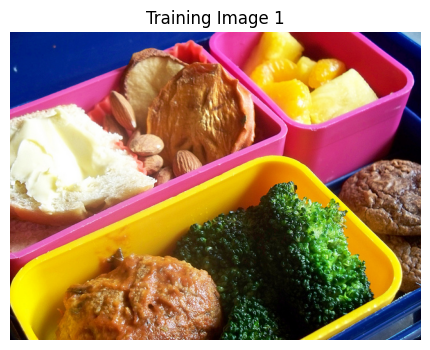

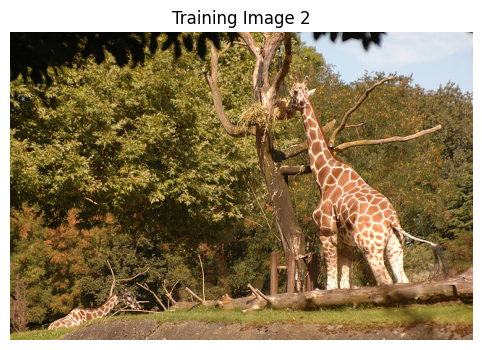

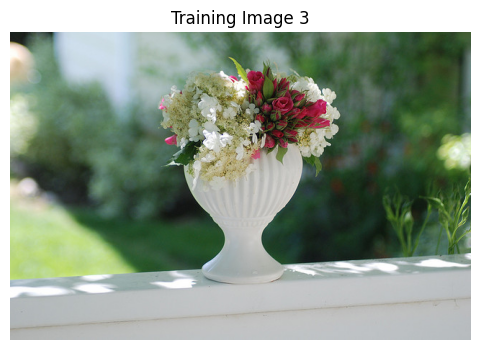

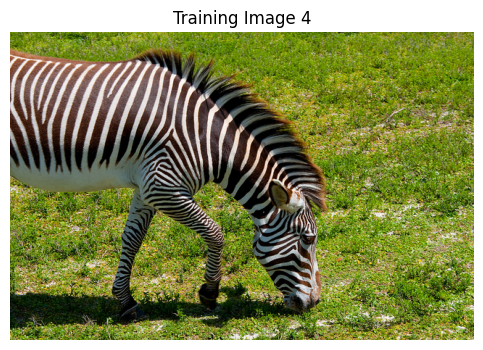

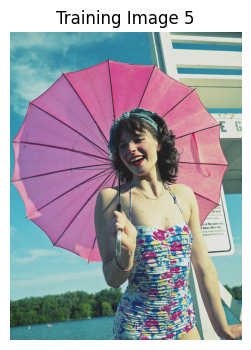

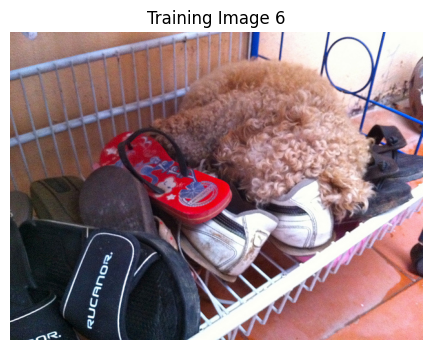

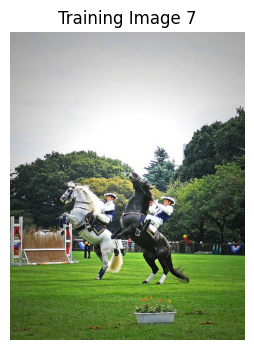

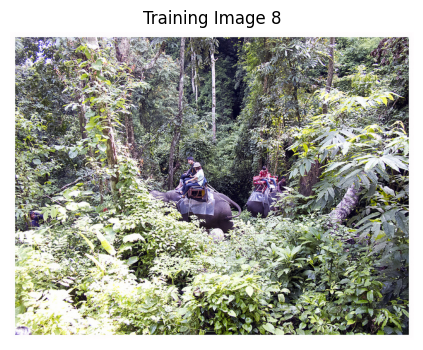

In [ ]:
# ============================================================
# Visualize Images
# ============================================================

for i in range(len(pil_images)):

    plt.figure(figsize=(6,4))
    plt.imshow(pil_images[i])
    plt.title(f"Training Image {i+1}")
    plt.axis("off")
    plt.show()

In [ ]:
# ============================================================
# Move Images to Device
# ============================================================

train_images = []

for img in batch_images:
    train_images.append(img.to(device))

train_targets = []

for target in batch_targets:

    train_targets.append({

        "boxes": target["boxes"].to(device),

        "labels": target["labels"].to(device)

    })

print("Training Batch Ready")

Training Batch Ready


In [ ]:
# ============================================================
# Build RetinaNet Model
# ============================================================

weights = RetinaNet_ResNet50_FPN_Weights.DEFAULT

model = retinanet_resnet50_fpn(weights=weights)

model = model.to(device)

print(model.backbone)
print(model.head)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.0005
)

BackboneWithFPN(
  (body): IntermediateLayerGetter(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): FrozenBatchNorm2d(64, eps=0.0)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): Bottleneck(
        (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn1): FrozenBatchNorm2d(64, eps=0.0)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): FrozenBatchNorm2d(64, eps=0.0)
        (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn3): FrozenBatchNorm2d(256, eps=0.0)
        (relu): ReLU(inplace=True)
        (downsample): Sequential(
          (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (1): FrozenBatchNorm2d(256, eps=0.0)
        )
      )
      (1): Bottleneck(
        (conv1): C

In [ ]:
# ============================================================
# Training
# ============================================================

model.train()

epochs = 3

for epoch in range(epochs):

    loss_dict = model(train_images, train_targets)

    total_loss = (
        loss_dict["classification"]
        +
        loss_dict["bbox_regression"]
    )

    optimizer.zero_grad()

    total_loss.backward()

    optimizer.step()

    print(f"Epoch {epoch+1}/{epochs} Loss : {total_loss:.4f}")

print("Training Completed")

Epoch 1/3 Loss : 8.4806
Epoch 2/3 Loss : 2.7835
Epoch 3/3 Loss : 1.9972
Training Completed


In [ ]:
# ============================================================
# Save Model
# ============================================================

torch.save(model.state_dict(),"one_stage_retinanet.pt")

print("Model Saved Successfully")

Model Saved Successfully


In [ ]:
# ============================================================
# Prediction
# ============================================================

model.eval()

test_index = 0

test_image = train_images[test_index]

test_pil = pil_images[test_index]

with torch.no_grad():

    prediction = model([test_image])[0]

boxes = prediction["boxes"]

labels = prediction["labels"]

scores = prediction["scores"]

threshold = 0.5

keep = scores >= threshold

boxes = boxes[keep].cpu().numpy()

labels = labels[keep].cpu().numpy()

scores = scores[keep].cpu().numpy()

print("Objects Detected :", len(boxes))

Objects Detected : 0


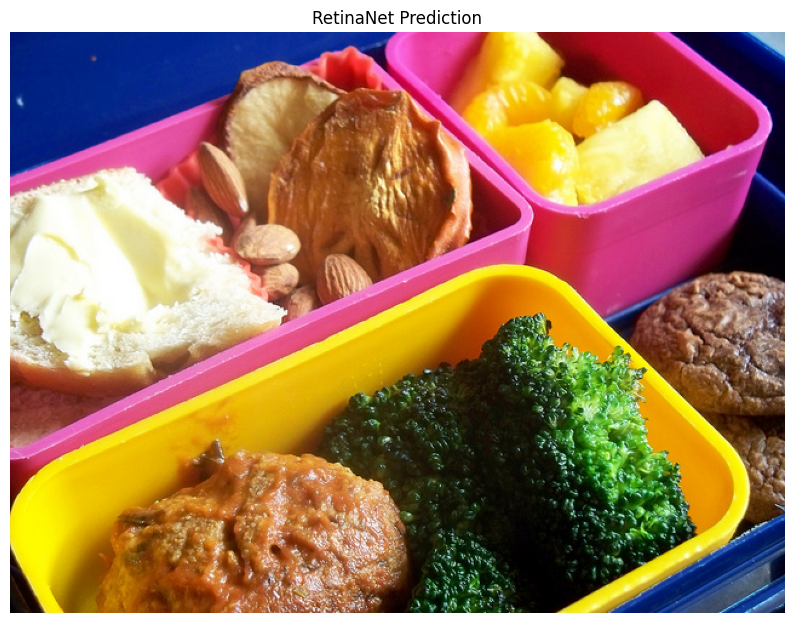

Prediction Completed


In [ ]:
# ============================================================
# Draw Bounding Boxes
# ============================================================

fig, ax = plt.subplots(figsize=(10,8))

ax.imshow(test_pil)

for box, label, score in zip(boxes, labels, scores):

    x1, y1, x2, y2 = box

    rect = patches.Rectangle(

        (x1,y1),

        x2-x1,

        y2-y1,

        linewidth=2,

        edgecolor="red",

        facecolor="none"

    )

    ax.add_patch(rect)

    if label < len(class_names):

        name = class_names[label]

    else:

        name = f"class_{label}"

    ax.text(

        x1,

        y1-5,

        f"{name} {score:.2f}",

        color="white",

        bbox=dict(facecolor="red", alpha=0.7)

    )

ax.set_title("RetinaNet Prediction")

ax.axis("off")

plt.show()

print("Prediction Completed")